# RM1 · ODEs for MRI: decay, recovery and rotation

**Part:** Math refresher · **Reading time:** ~25 min · **Pass 1 overview:** [What MRI measures](../pass1_big_picture/P1.1_What_MRI_Measures.ipynb) · **Refreshers you may want:** [RM2 Complex numbers & rotations](RM2_Complex_Numbers_and_Rotations.ipynb)

Almost all of MRI physics is contained in one equation, the **Bloch equation**, and it is an
**ordinary differential equation (ODE)**: it tells you how fast the magnetization changes *right now*,
and you have to work out where it ends up. Luckily, MRI only needs a tiny corner of ODE theory:
exponential decay, exponential recovery, rotation, and the combination of the three.
This refresher walks through each one slowly, solves it by hand, checks it numerically, and shows
which numerical tricks the simulator in `mri_tools` uses (and why the naive one fails).

## Learning goals

After this notebook you can

1. Solve $dy/dt = -y/\tau$ and $dy/dt = (y_{eq}-y)/\tau$ by **separation of variables** and by an **integrating factor**, and write down the general solution of a first-order linear ODE with constant coefficients from memory ("final value + (initial − final)·e^{−t/τ}").
2. Find a **steady state** by setting the time derivative to zero, including the "repeated kick" steady state used for fast MRI sequences.
3. Solve the coupled system $dx/dt=\omega y,\ dy/dt=-\omega x$ with the complex variable $z=x+iy$ and recognise it as a **clockwise rotation**.
4. Write a Bloch-type equation as a matrix ODE $d\vec M/dt = A\vec M+\vec b$ and solve it with a matrix exponential.
5. Explain why the **forward Euler** method spirals outwards for rotations, and why an exact rotation step plus an exact relaxation step (**operator splitting**, as in `mt.bloch_simulate`) is the method of choice.

## Symbols used in this notebook

| Symbol | Meaning (plain words) | SI unit | Typical value / remark |
|---|---|---|---|
| $t$ | time | s | |
| $t'$ | dummy integration variable (a "running" time inside an integral) | s | elsewhere in the series written $\tau$ |
| $y(t)$ | a generic quantity that changes in time | any | stands for $M_z$, $\lvert M_{xy}\rvert$, … |
| $y_0=y(0)$ | initial value (initial condition) | same as $y$ | |
| $\tau$ | **time constant** of a decay/recovery (in this notebook only!) | s | becomes $T_1$ or $T_2$ |
| $y_{eq}$ | equilibrium value that $y$ relaxes towards | same as $y$ | becomes $M_0$ |
| $a,\ c(t)$ | coefficients of the general linear ODE $dy/dt+ay=c(t)$ | s⁻¹, units of $y$/s | $a=1/\tau$ |
| $\omega$ | angular frequency of a rotation | rad/s | $\omega=2\pi f$ |
| $f$ | ordinary frequency | Hz | |
| $x(t),\ y(t)$ | two coupled components (in section 5: $M_x$, $M_y$) | – | |
| $z=x+iy$ | complex variable combining them | – | $i=\sqrt{-1}$ |
| $\vec M=[M_x,M_y,M_z]^T$ | magnetization vector | normalized ($M_0=1$) | physically A/m |
| $M_0$ | equilibrium magnetization | normalized, $=1$ | |
| $\vec B=[B_x,B_y,B_z]^T$ | magnetic field (flux density) | T | |
| $\gamma$ | gyromagnetic ratio (angular) | rad s⁻¹ T⁻¹ | $2.675\times10^8$ for ¹H |
| $\bar\gamma=\gamma/2\pi$ | gyromagnetic ratio | Hz/T | 42.58 MHz/T |
| $T_1,\ T_2$ | longitudinal / transverse relaxation **time constants** | s | $T_1$ 0.25–4 s, $T_2$ 10 ms–2 s |
| $A,\ \vec b$ | system matrix and constant forcing vector of $d\vec M/dt=A\vec M+\vec b$ | s⁻¹ | |
| $e^{At}$ | matrix exponential | – | `scipy.linalg.expm` |
| $\vec M_{ss}$ | steady state, where $d\vec M/dt=0$ | normalized | |
| $\Delta t$ | numerical time step | s | 1–10 µs in RF simulations |
| $\theta$ | flip angle of an RF pulse | rad (or °) | |
| $TR$ | repetition time | s | 3 ms – 10 s |
| $E_1=e^{-TR/T_1}$ | recovery factor per TR | – | |

> **⚠️ Common confusion:** in this refresher $\tau$ is a **time constant** (because that is what most
> ODE textbooks use). In the rest of the series (see [Notation](../reference/Notation_and_Symbols.ipynb)) $\tau$ is a *dummy
> integration variable*; here we use $t'$ for that job. In MRI the time constants get their own names, $T_1$ and $T_2$.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))   # make ../mri_tools.py importable
import numpy as np
import matplotlib.pyplot as plt
import mri_tools as mt
mt.setup_plots()
%matplotlib inline

from scipy.linalg import expm   # matrix exponential, used in sections 5-7

## 1. What an ODE is (in one picture)

An **ordinary differential equation** is a rule that gives the **slope** of an unknown function in
terms of its current value (and possibly time):

$$\frac{dy}{dt} = f\big(y(t), t\big).$$

In words: "if you are at value $y$ at time $t$, you are currently changing at rate $f(y,t)$."
A **solution** is a whole function $y(t)$ whose slope obeys this rule at every instant. The rule alone
allows infinitely many solutions; picking the **initial condition** $y(0)=y_0$ selects exactly one.

The picture below draws the rule $dy/dt=-y/\tau$ as little slope arrows (a **direction field**) and a few
solutions, one for each starting value. Each solution simply "follows the arrows".

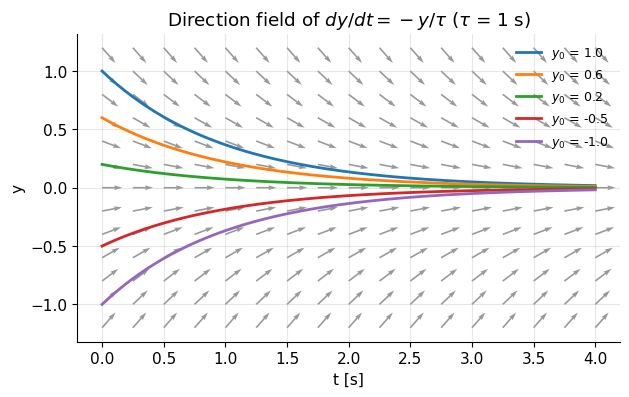

In [2]:
tau = 1.0                                    # time constant [s]
T, Y = np.meshgrid(np.linspace(0, 4, 17), np.linspace(-1.2, 1.2, 13))
slope = -Y / tau                             # dy/dt at every grid point
L = np.sqrt(1 + slope**2)                    # normalise arrow length
plt.figure(figsize=(7, 4))
plt.quiver(T, Y, 1 / L, slope / L, angles="xy", color="0.6", width=0.003)
t = np.linspace(0, 4, 200)
for y0 in [1.0, 0.6, 0.2, -0.5, -1.0]:
    plt.plot(t, y0 * np.exp(-t / tau), lw=2, label=f"$y_0$ = {y0}")
plt.xlabel("t [s]"); plt.ylabel("y"); plt.title(r"Direction field of $dy/dt=-y/\tau$ ($\tau$ = 1 s)")
plt.legend(loc="upper right", fontsize=9); plt.show()

Every curve heads towards $y=0$, where the slope is zero: different initial conditions, same "physics".

## 2. Exponential decay: $dy/dt = -y/\tau$

This says: *the rate of loss is proportional to how much is left.* The more you have, the faster you lose it.

**Solving by separation of variables (step by step).**

1. Move everything with $y$ to the left and everything with $t$ to the right (treat $dy$ and $dt$ like small numbers):
   $$\frac{dy}{y} = -\frac{dt}{\tau}.$$
2. Integrate both sides, from the start ($t'=0$, value $y_0$) to "now" ($t'=t$, value $y$):
   $$\int_{y_0}^{y}\frac{dy'}{y'} = -\int_0^{t}\frac{dt'}{\tau}.$$
3. Use $\int dy/y=\ln|y|$: $\quad \ln y - \ln y_0 = -t/\tau \;\Rightarrow\; \ln(y/y_0) = -t/\tau.$
4. Exponentiate both sides:

$$y(t) = y_0\,e^{-t/\tau}.$$

In words: the quantity shrinks by the same **factor** $e^{-1}\approx 0.37$ every time a time $\tau$ passes.
Where: $y_0$ = starting value, $\tau$ = time constant [s].

**Check** (always worth 10 seconds): differentiate, $dy/dt = y_0 e^{-t/\tau}\cdot(-1/\tau) = -y/\tau$ ✓, and $y(0)=y_0$ ✓.

Useful numbers to memorise:

| time | $t=\tau$ | $t=\tau\ln 2\approx0.69\tau$ | $t=3\tau$ | $t=5\tau$ |
|---|---|---|---|---|
| fraction left $e^{-t/\tau}$ | 37 % | 50 % (half-life) | 5 % | 0.7 % |

The **rate** $R=1/\tau$ (unit s⁻¹) is the same information. In MRI, $R_2=1/T_2$ and $R_1=1/T_1$ are called
relaxation *rates*, while $T_1$, $T_2$ are relaxation *time constants*.

**In MRI:** after excitation the transverse magnetization obeys $d|M_{xy}|/dt=-|M_{xy}|/T_2$, so
$|M_{xy}(t)| = |M_{xy}(0)|\,e^{-t/T_2}$ — the **$T_2$ decay**. With $T_2\approx 80$ ms (white matter at 1.5 T),
the signal at echo time $TE = 80$ ms is 37 % of its initial value.

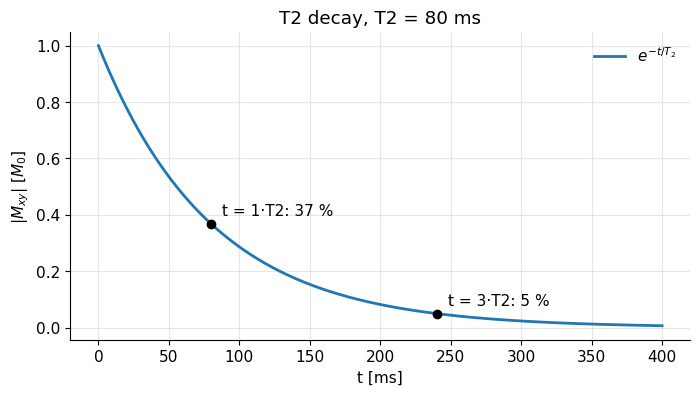

In [3]:
T2 = 80e-3                        # transverse relaxation time constant [s] (white-matter-like, 1.5 T)
t = np.linspace(0, 400e-3, 400)   # time [s]
Mxy = 1.0 * np.exp(-t / T2)       # exact solution with Mxy(0) = 1

plt.plot(t * 1e3, Mxy, lw=2, label=r"$e^{-t/T_2}$")
for n, txt in [(1, "37 %"), (3, "5 %")]:
    plt.plot(n * T2 * 1e3, np.exp(-n), "ko"); plt.annotate(f"t = {n}·T2: {txt}", (n * T2 * 1e3 + 8, np.exp(-n) + 0.03))
plt.xlabel("t [ms]"); plt.ylabel(r"$|M_{xy}|$ [$M_0$]"); plt.title("T2 decay, T2 = 80 ms"); plt.legend(); plt.show()

The curve loses 63 % in the first $T_2$, then 63 % of the rest in the next $T_2$, and so on.

## 3. Exponential recovery: $dy/dt = (y_{eq}-y)/\tau$

Now the rate is proportional to the **distance from equilibrium** $y_{eq}$: far from equilibrium → fast
change, close to it → slow change. If $y<y_{eq}$ the slope is positive (it grows); if $y>y_{eq}$ it shrinks.

### Method A: shift the variable (reduce to section 2)

Define the "distance from equilibrium" $u = y - y_{eq}$. Because $y_{eq}$ is constant, $du/dt = dy/dt$, so
$du/dt = -u/\tau$, which we already solved: $u(t)=u_0e^{-t/\tau}$. Substituting back:

$$y(t) = y_{eq} + \big(y_0 - y_{eq}\big)\,e^{-t/\tau}.$$

In words: **final value + (initial value − final value) × e^{−t/τ}**. This one-line recipe covers every
relaxation formula in MRI.

### Method B: integrating factor (works for *any* forcing)

Write the ODE in the standard form of a **first-order linear ODE with constant coefficient $a$**:

$$\frac{dy}{dt} + a\,y = c(t).$$

where $a$ [s⁻¹] is a constant rate and $c(t)$ [units of $y$ per s] is a "source" or "input". (Recovery: $a=1/\tau$, $c=y_{eq}/\tau$.)

<details><summary><b>📐 Derivation (optional): the integrating factor, step by step</b></summary>

1. Multiply both sides by $e^{at}$ (the *integrating factor*): $\;e^{at}\dfrac{dy}{dt} + a e^{at} y = e^{at}c(t)$.
2. The left side is exactly the product rule for $\dfrac{d}{dt}\big(e^{at}y\big)$. So $\;\dfrac{d}{dt}\big(e^{at}y\big) = e^{at}c(t)$.
3. Integrate from $0$ to $t$: $\;e^{at}y(t) - y_0 = \displaystyle\int_0^t e^{at'}c(t')\,dt'$.
4. Multiply by $e^{-at}$:
$$y(t) = y_0e^{-at} + \int_0^t e^{-a(t-t')}\,c(t')\,dt'.$$
5. For constant $c$: $\int_0^t e^{-a(t-t')}dt' = (1-e^{-at})/a$, hence $y(t) = \dfrac{c}{a} + \Big(y_0-\dfrac{c}{a}\Big)e^{-at}$.

</details>

The **general solution** is

$$y(t) = \underbrace{y_0\,e^{-at}}_{\text{memory of the start, fades}} \;+\; \underbrace{\int_0^t e^{-a(t-t')}\,c(t')\,dt'}_{\text{response to the input}}.$$

In words: the initial value decays away, and every past input $c(t')$ contributes with a weight
$e^{-a(t-t')}$ that fades with its age $t-t'$. Where: $t'$ = time at which the input happened.
For constant $c$ this gives $y = c/a + (y_0 - c/a)e^{-at}$; with $a=1/\tau$, $c=y_{eq}/\tau$ that is again the recipe above ($c/a=y_{eq}$).

> **📐 Math note:** the integral is a **convolution** of the input $c(t)$ with the decaying exponential
> $e^{-at}$ (for $t\ge0$). A linear ODE is a *linear, time-invariant system* — the same idea as the
> filters you know from signal processing ([RM4 Fourier properties](RM4_Fourier_Properties.ipynb)).

**In MRI:** the longitudinal magnetization recovers towards $M_0$ with time constant $T_1$:

$$M_z(t) = M_0 + \big(M_z(0) - M_0\big)\,e^{-t/T_1}.$$

where $M_z(0)$ is the value right after an RF pulse. After a 90° pulse $M_z(0)=0$, so $M_z = M_0(1-e^{-t/T_1})$.
After a 180° (inversion) pulse $M_z(0)=-M_0$, so $M_z = M_0(1-2e^{-t/T_1})$, which crosses zero at
$t = T_1\ln 2$ — the "null point" used in inversion-recovery sequences (FLAIR, STIR).

Mz(1 s) after inversion: formula 0.3416,  mt.relax 0.3416


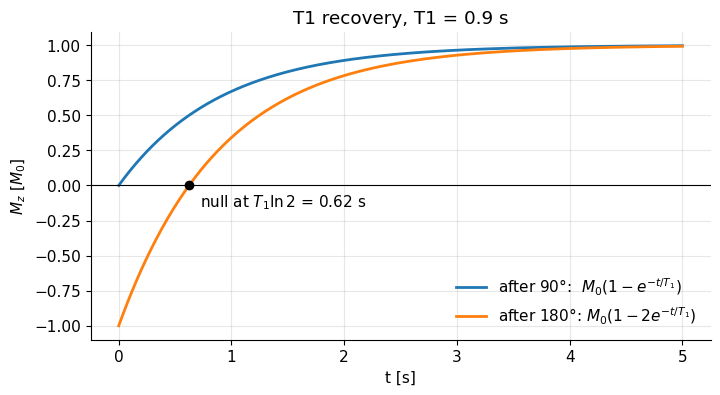

In [4]:
T1 = 0.9                       # longitudinal relaxation time constant [s] (gray-matter-like, 1.5 T)
M0 = 1.0
t = np.linspace(0, 5, 500)     # time [s]
Mz_after_90 = M0 + (0.0 - M0) * np.exp(-t / T1)
Mz_after_180 = M0 + (-M0 - M0) * np.exp(-t / T1)

# mri_tools uses exactly this exact solution for one step dt:  mt.relax(M, dt, T1, T2)
Mz_check = mt.relax(np.array([0.0, 0.0, -1.0]), dt=1.0, T1=T1, T2=np.inf)[2]
print(f"Mz(1 s) after inversion: formula {M0 + (-2*M0)*np.exp(-1/T1):.4f},  mt.relax {Mz_check:.4f}")

plt.plot(t, Mz_after_90, lw=2, label="after 90°:  $M_0(1-e^{-t/T_1})$")
plt.plot(t, Mz_after_180, lw=2, label="after 180°: $M_0(1-2e^{-t/T_1})$")
plt.axhline(0, color="k", lw=0.8)
plt.plot(T1 * np.log(2), 0, "ko"); plt.annotate(r"null at $T_1\ln2$ = %.2f s" % (T1 * np.log(2)), (T1 * np.log(2) + 0.1, -0.15))
plt.xlabel("t [s]"); plt.ylabel(r"$M_z$ [$M_0$]"); plt.title("T1 recovery, T1 = 0.9 s"); plt.legend(); plt.show()

Both curves approach $M_0$ with the same time constant; only the starting point differs — exactly the "final + (initial − final)·e^{−t/τ}" recipe.

## 4. Steady states: where $dy/dt = 0$

A **steady state** is a value that the ODE does not change: set the derivative to zero and solve.
For recovery, $0=(y_{eq}-y)/\tau \Rightarrow y_{ss}=y_{eq}$: left alone, $M_z$ ends at $M_0$.

MRI sequences are more interesting: they **kick** the magnetization with an RF pulse every repetition
time $TR$ and let it recover in between. After enough repetitions the magnetization just before each pulse is
the same every time — a **dynamic steady state**. The trick is the same: write one period as a map
and look for its **fixed point**.

For a spoiled gradient echo (transverse magnetization destroyed after each readout): let $M_z^-$ be the value
just before a pulse of flip angle $\theta$. The pulse leaves $M_z^-\cos\theta$, and recovery over $TR$ gives

$$M_{z,n+1}^- = M_0 + \big(M_{z,n}^-\cos\theta - M_0\big)E_1, \qquad E_1 = e^{-TR/T_1}.$$

In words: each period applies the recovery recipe, starting from the value the pulse left behind.
Setting $M_{z,n+1}^-=M_{z,n}^-=M_{ss}$ and solving the linear equation gives

$$M_{ss} = M_0\,\frac{1-E_1}{1-E_1\cos\theta},\qquad \text{signal} = M_{ss}\sin\theta.$$

where $\theta$ = flip angle [rad], $TR$ = repetition time [s], $T_1$ [s]. This is the spoiled-GRE ("FLASH") signal equation implemented in `mt.spoiled_gre_signal`.

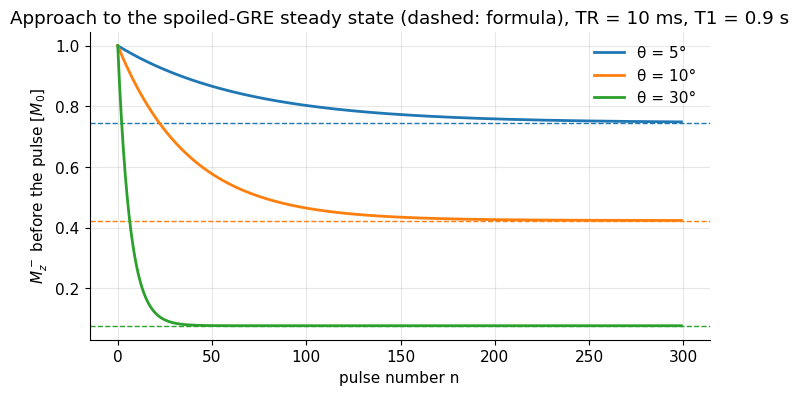

In [5]:
T1, TR = 0.9, 10e-3            # [s]
E1 = np.exp(-TR / T1)
n_TR = 300
plt.figure(figsize=(8, 4))
for theta_deg in [5, 10, 30]:
    th = np.deg2rad(theta_deg)
    Mz = np.empty(n_TR); Mz[0] = 1.0                     # start fully relaxed
    for n in range(n_TR - 1):
        Mz[n + 1] = 1.0 + (Mz[n] * np.cos(th) - 1.0) * E1   # one TR: kick, then recover
    Mss = mt.spoiled_gre_signal(th, TE=0.0, TR=TR, T1=T1, T2star=np.inf) / np.sin(th)
    line, = plt.plot(Mz, lw=2, label=f"θ = {theta_deg}°")
    plt.axhline(Mss, color=line.get_color(), ls="--", lw=1)
plt.xlabel("pulse number n"); plt.ylabel(r"$M_z^-$ before the pulse [$M_0$]")
plt.title("Approach to the spoiled-GRE steady state (dashed: formula), TR = 10 ms, T1 = 0.9 s")
plt.legend(); plt.show()

Each iteration converges to the dashed line predicted by the fixed-point formula; larger flip angles reach a lower steady state, and reach it faster (the per-TR factor $E_1\cos\theta$ is smaller).

## 5. Two coupled ODEs → rotation

Now two quantities that drive each other:

$$\frac{dx}{dt} = \omega\,y, \qquad \frac{dy}{dt} = -\omega\,x.$$

In words: the rate of change of $x$ is set by $y$ and vice versa, with opposite signs. Where: $\omega$ = angular frequency [rad/s].
In matrix form, with the vector $[x,y]^T$:

$$\frac{d}{dt}\begin{bmatrix}x\\y\end{bmatrix} = \begin{bmatrix}0&\omega\\-\omega&0\end{bmatrix}\begin{bmatrix}x\\y\end{bmatrix}.$$

The velocity $[\omega y,-\omega x]$ is always **perpendicular** to the position $[x,y]$ (their dot product is zero), so the
point never gets closer to or further from the origin: it moves on a circle.

**The complex-variable trick.** Combine the two real equations into one complex one with $z = x + iy$:

$$\frac{dz}{dt} = \frac{dx}{dt} + i\frac{dy}{dt} = \omega y - i\omega x = -i\omega\,(x + iy) = -i\omega\, z.$$

This is the decay equation of section 2 with the "rate" $-i\omega$ instead of $-1/\tau$, so the same solution applies:

$$z(t) = z_0\,e^{-i\omega t}.$$

In words: $z$ keeps its length $|z_0|$ and its angle decreases at rate $\omega$ — a **clockwise** rotation
(see [RM2](RM2_Complex_Numbers_and_Rotations.ipynb) for $e^{-i\omega t}$). Taking real and imaginary parts:

$$x(t) = x_0\cos\omega t + y_0\sin\omega t,\qquad y(t) = -x_0\sin\omega t + y_0\cos\omega t.$$

**In MRI:** these are exactly the equations for $M_x$, $M_y$ in a field $B_0$ along $z$ with $\omega=\gamma B_0$:
precession, $M_{xy}(t)=M_{xy}(0)e^{-i\omega t}$. Add $T_2$ decay and the complex rate becomes $-i\omega-1/T_2$:

$$M_{xy}(t) = M_{xy}(0)\,e^{-i\omega t}\,e^{-t/T_2}.$$

In words: a decaying clockwise spiral — the **free induction decay (FID)**.

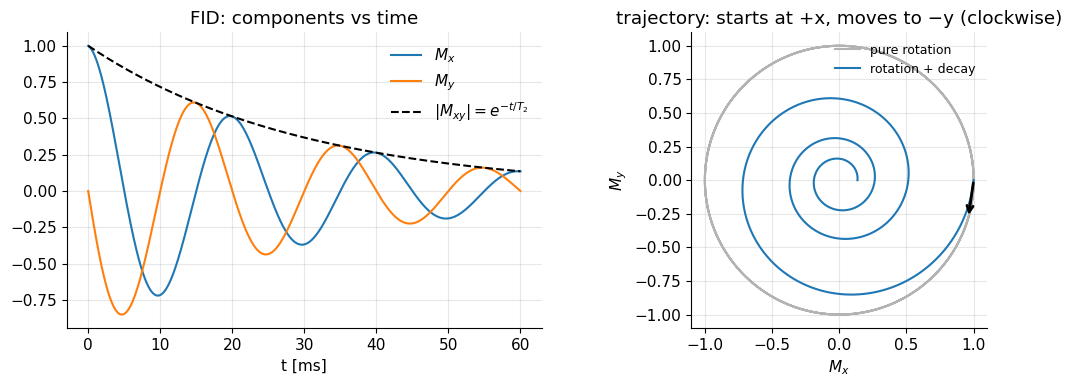

In [6]:
f = 50.0                         # precession frequency [Hz] (e.g. off-resonance in the rotating frame)
w = 2 * np.pi * f                # angular frequency [rad/s]
T2 = 30e-3                       # [s]
t = np.linspace(0, 60e-3, 1000)  # [s]
z0 = 1.0 + 0j                    # start along +x
z = z0 * np.exp(-1j * w * t)               # pure rotation
z_fid = z0 * np.exp(-1j * w * t - t / T2)  # rotation + T2 decay

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(t * 1e3, z_fid.real, label=r"$M_x$"); ax[0].plot(t * 1e3, z_fid.imag, label=r"$M_y$")
ax[0].plot(t * 1e3, np.abs(z_fid), "k--", label=r"$|M_{xy}|=e^{-t/T_2}$")
ax[0].set_xlabel("t [ms]"); ax[0].set_title("FID: components vs time"); ax[0].legend()
ax[1].plot(z.real, z.imag, color="0.7", label="pure rotation")
ax[1].plot(z_fid.real, z_fid.imag, label="rotation + decay")
ax[1].annotate("", xy=(z[15].real, z[15].imag), xytext=(1, 0), arrowprops=dict(arrowstyle="->", lw=2))
ax[1].set_aspect("equal"); ax[1].set_xlabel(r"$M_x$"); ax[1].set_ylabel(r"$M_y$")
ax[1].set_title("trajectory: starts at +x, moves to −y (clockwise)"); ax[1].legend(fontsize=9)
plt.tight_layout(); plt.show()

$M_x$ and $M_y$ oscillate 90° out of phase inside a decaying envelope; in the plane the tip spirals clockwise into the origin.

> **📐 Math note — matrix exponential.** Any linear system $d\vec v/dt = A\vec v$ with constant $A$ has the
> solution $\vec v(t) = e^{At}\vec v(0)$, where $e^{At}=I+At+(At)^2/2!+\dots$ is the **matrix exponential**
> (`scipy.linalg.expm`). The eigenvalues of $A$ tell you the behaviour: negative real → decay, imaginary $\pm i\omega$ →
> oscillation/rotation. For our rotation matrix the eigenvalues are $\pm i\omega$, and $e^{At}$ is a rotation matrix:

In [7]:
A = np.array([[0, w], [-w, 0]])                 # dx/dt = w y, dy/dt = -w x
tt = 3e-3                                       # [s]
print("eigenvalues of A [rad/s]:", np.linalg.eigvals(A))
print("expm(A t):\n", np.round(expm(A * tt), 4))
print("[[cos wt, sin wt], [-sin wt, cos wt]]:\n",
      np.round(np.array([[np.cos(w*tt), np.sin(w*tt)], [-np.sin(w*tt), np.cos(w*tt)]]), 4))

eigenvalues of A [rad/s]: [0.+314.15926536j 0.-314.15926536j]
expm(A t):
 [[ 0.5878  0.809 ]
 [-0.809   0.5878]]
[[cos wt, sin wt], [-sin wt, cos wt]]:
 [[ 0.5878  0.809 ]
 [-0.809   0.5878]]


The matrix exponential reproduces the clockwise rotation matrix exactly: the "exponential" solution works for systems too.

## 6. Preview: the Bloch equation as a matrix ODE

The [Bloch equation](../pass2_deep_dive/A2_Bloch_Equation.ipynb) combines precession and relaxation:

$$\frac{d\vec M}{dt} = \gamma\,\vec M\times\vec B \;-\; \begin{bmatrix}M_x/T_2\\ M_y/T_2\\ (M_z-M_0)/T_1\end{bmatrix}.$$

In words: the magnetization vector $\vec M$ rotates about the field $\vec B$ (the cross-product term, see
[RM2](RM2_Complex_Numbers_and_Rotations.ipynb)), its transverse part decays with $T_2$ and its longitudinal part recovers to $M_0$ with $T_1$.
Where: $\gamma$ = gyromagnetic ratio [rad s⁻¹ T⁻¹], $\vec B$ = field [T] (in the rotating frame: RF field in $x,y$ plus any off-resonance along $z$).

The cross product is linear in $\vec M$, so it can be written as a matrix times $\vec M$:
$\vec M\times\vec B = \begin{bmatrix}0&B_z&-B_y\\-B_z&0&B_x\\B_y&-B_x&0\end{bmatrix}\vec M$.
For a constant field, the Bloch equation therefore has the familiar form

$$\frac{d\vec M}{dt} = A\,\vec M + \vec b,\quad
A = \begin{bmatrix}-1/T_2 & \gamma B_z & -\gamma B_y\\ -\gamma B_z & -1/T_2 & \gamma B_x\\ \gamma B_y & -\gamma B_x & -1/T_1\end{bmatrix},\quad
\vec b = \begin{bmatrix}0\\0\\M_0/T_1\end{bmatrix}.$$

where $A$ [s⁻¹] contains rotation (off-diagonal) and relaxation (diagonal), and $\vec b$ [s⁻¹] is the "source" that pulls $M_z$ back up.

It is the vector version of $dy/dt+ay=c$, and the solution is the vector version of the recipe:

$$\vec M_{ss} = -A^{-1}\vec b\quad(\text{set } d\vec M/dt=0),\qquad \vec M(t) = \vec M_{ss} + e^{At}\big(\vec M(0)-\vec M_{ss}\big).$$

In words: steady state + (decaying, rotating) memory of the difference between start and steady state.

With only $B_z$ the steady state is $[0,0,M_0]$ (equilibrium). With a **continuous** RF field the steady state has reduced $M_z$
("saturation") — computed below in two lines.

In [8]:
def bloch_matrix(B, T1, T2, M0=1.0, gamma=mt.GAMMA):
    """A and b of dM/dt = A M + b for a constant field B = [Bx, By, Bz] [T] (rotating frame)."""
    Bx, By, Bz = B
    A = np.array([[-1 / T2,       gamma * Bz, -gamma * By],
                  [-gamma * Bz,   -1 / T2,     gamma * Bx],
                  [ gamma * By,   -gamma * Bx, -1 / T1]])
    b = np.array([0.0, 0.0, M0 / T1])
    return A, b

T1, T2 = 1.0, 0.1                                 # [s]
for f1 in [0.0, 1.0, 10.0]:                       # RF strength expressed as gamma_bar*B1 [Hz]
    A, b = bloch_matrix([f1 / mt.GAMMA_BAR, 0, 0], T1, T2)
    Mss = -np.linalg.solve(A, b)
    print(f"continuous RF with gamma_bar*B1 = {f1:4.1f} Hz (B1 = {f1/mt.GAMMA_BAR*1e9:5.1f} nT):  M_ss = {np.round(Mss, 3)}")

continuous RF with gamma_bar*B1 =  0.0 Hz (B1 =   0.0 nT):  M_ss = [0. 0. 1.]
continuous RF with gamma_bar*B1 =  1.0 Hz (B1 =  23.5 nT):  M_ss = [0.    0.127 0.202]
continuous RF with gamma_bar*B1 = 10.0 Hz (B1 = 234.9 nT):  M_ss = [0.    0.016 0.003]


Even a very weak continuous RF field (here 23–235 nT, i.e. $\bar\gamma B_1$ = 1–10 Hz) drives $M_z$ almost to zero when it acts for long compared with $T_1$: the spins are **saturated**. Pulsed sequences avoid this by switching RF on only briefly.

## 7. Solving ODEs numerically: why Euler fails for rotation

When the field changes in time (RF pulses, gradients) we step through time numerically.
The simplest method, **forward Euler**, follows the current slope for one step $\Delta t$:

$$y_{n+1} = y_n + \Delta t\, f(y_n).$$

In words: "assume the slope stays constant during the step". For the rotation $dz/dt=-i\omega z$ one Euler step is
$z_{n+1} = (1-i\omega\Delta t)\,z_n$, and

$$|1-i\omega\Delta t| = \sqrt{1+(\omega\Delta t)^2} > 1.$$

So **every step increases the length** of $z$ a little: the numerical magnetization spirals outwards and grows
without bound — physically impossible (precession conserves $|\vec M|$). The **exact rotation step**
$z_{n+1}=e^{-i\omega\Delta t}z_n$ has $|e^{-i\omega\Delta t}|=1$ and is exact for *any* $\Delta t$ as long as the field is constant during the step.

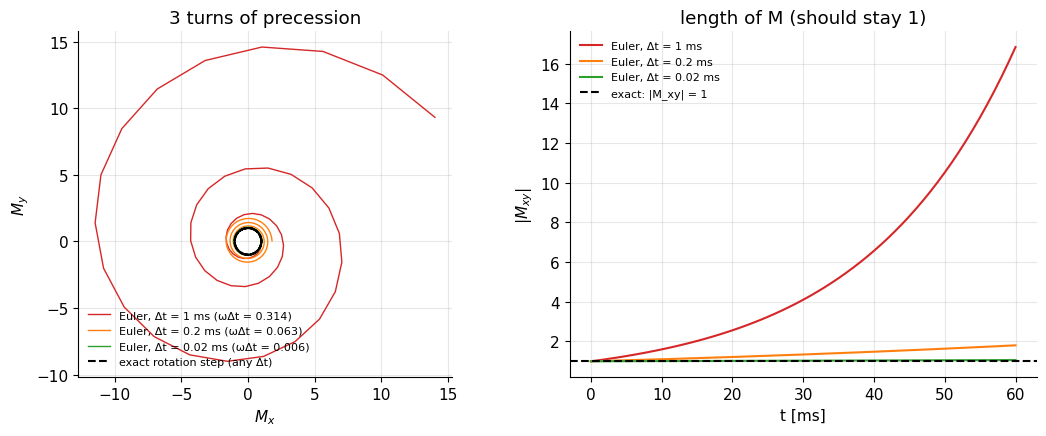

In [9]:
f = 50.0; w = 2 * np.pi * f              # [Hz], [rad/s]
t_end = 60e-3                            # 3 full turns [s]
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
for dt, col in [(1e-3, "C3"), (2e-4, "C1"), (2e-5, "C2")]:
    n = int(round(t_end / dt))
    z_euler = np.empty(n + 1, complex); z_euler[0] = 1
    z_exact = np.empty(n + 1, complex); z_exact[0] = 1
    for k in range(n):
        z_euler[k + 1] = z_euler[k] + dt * (-1j * w * z_euler[k])   # forward Euler
        z_exact[k + 1] = np.exp(-1j * w * dt) * z_exact[k]           # exact rotation step
    tk = np.arange(n + 1) * dt
    ax[0].plot(z_euler.real, z_euler.imag, color=col, lw=1, label=f"Euler, Δt = {dt*1e3:g} ms (ωΔt = {w*dt:.3f})")
    ax[1].plot(tk * 1e3, np.abs(z_euler), color=col, label=f"Euler, Δt = {dt*1e3:g} ms")
ax[0].plot(z_exact.real, z_exact.imag, "k--", lw=1.5, label="exact rotation step (any Δt)")
ax[0].set_aspect("equal"); ax[0].set_xlabel(r"$M_x$"); ax[0].set_ylabel(r"$M_y$"); ax[0].legend(fontsize=8, loc="lower left")
ax[0].set_title("3 turns of precession")
ax[1].axhline(1, color="k", ls="--", label="exact: |M_xy| = 1")
ax[1].set_xlabel("t [ms]"); ax[1].set_ylabel(r"$|M_{xy}|$"); ax[1].set_title("length of M (should stay 1)"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

With $\omega\Delta t\approx0.3$ Euler's magnetization has grown by a factor ≈ 17 after three turns; with Δt = 0.2 ms it is still 1.8× too long, and even with Δt = 0.02 ms it is 6 % too long. The exact rotation step stays on the unit circle.

Euler has a related problem for decay: $y_{n+1}=(1-\Delta t/\tau)y_n$ oscillates in sign if $\Delta t>\tau$ and **blows up** if $\Delta t>2\tau$
(a short $T_2$ of 1 ms would force $\Delta t<2$ ms). The exact step $y_{n+1}=e^{-\Delta t/\tau}y_n$ never misbehaves.

### Operator splitting: what `mt.bloch_simulate` does

Within each time step, `mt.bloch_simulate` treats the field as constant and applies two **exact** sub-steps:

1. `mt.bloch_rotate`: rotate $\vec M$ about $\vec B$ by the angle $\gamma|\vec B|\Delta t$ (clockwise, left-handed);
2. `mt.relax`: apply exact $T_2$ decay to $M_x, M_y$ and exact $T_1$ recovery to $M_z$.

This is called **operator splitting**: split $A\vec M+\vec b$ into a "rotation part" and a "relaxation part",
solve each exactly, apply them one after the other. It is not perfectly exact, because rotating then
relaxing is not the same as doing both simultaneously when the rotation axis is not $z$ (the two
operations do not commute). The error shrinks proportionally to $\Delta t$, and — crucially — the
method never grows $|\vec M|$. Below we compare Euler and splitting against the exact matrix-exponential
solution for an RF pulse with strong relaxation.

exact final M: [0.2726 0.4343 0.205 ]


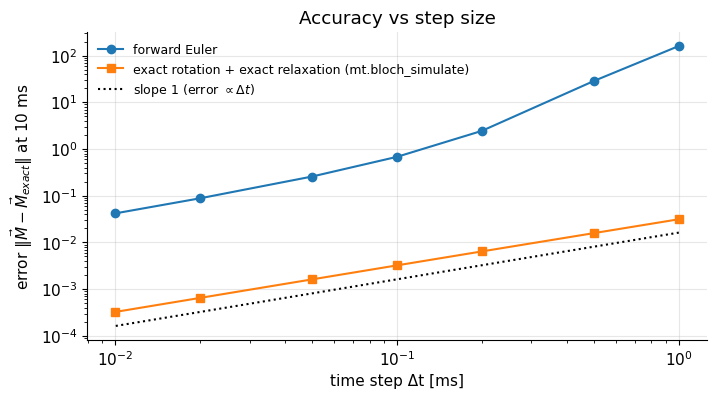

In [10]:
# Test case (rotating frame): constant RF along x plus off-resonance, short T1/T2 so relaxation matters
T1, T2 = 20e-3, 10e-3           # [s]
f1, df = 200.0, 100.0           # gamma_bar*B1 [Hz] and off-resonance [Hz]
B = np.array([f1 / mt.GAMMA_BAR, 0.0, df / mt.GAMMA_BAR])   # field in the rotating frame [T]
t_end = 10e-3                   # [s]
M_start = np.array([0.0, 0.0, 1.0])

# exact solution via the augmented 4x4 trick: d/dt [M; 1] = [[A, b], [0, 0]] [M; 1]
A, b = bloch_matrix(B, T1, T2)
Aug = np.zeros((4, 4)); Aug[:3, :3] = A; Aug[:3, 3] = b
M_exact = (expm(Aug * t_end) @ np.r_[M_start, 1.0])[:3]

dts = np.array([1e-3, 5e-4, 2e-4, 1e-4, 5e-5, 2e-5, 1e-5])
err_euler, err_split = [], []
for dt in dts:
    n = int(round(t_end / dt))
    M = M_start.copy()
    for _ in range(n):
        M = M + dt * (A @ M + b)                     # forward Euler
    err_euler.append(np.linalg.norm(M - M_exact))
    b1 = np.full(n, B[0] + 1j * B[1])                # constant RF envelope [T]
    _, M_split = mt.bloch_simulate(B1=b1, dt=dt, M_init=M_start, T1=T1, T2=T2, df=df, return_all=False)
    err_split.append(np.linalg.norm(M_split[0] - M_exact))

print("exact final M:", np.round(M_exact, 4))
plt.loglog(dts * 1e3, err_euler, "o-", label="forward Euler")
plt.loglog(dts * 1e3, err_split, "s-", label="exact rotation + exact relaxation (mt.bloch_simulate)")
plt.loglog(dts * 1e3, 0.5 * err_split[-1] * dts / dts[-1], "k:", label=r"slope 1 (error $\propto\Delta t$)")
plt.xlabel("time step Δt [ms]"); plt.ylabel(r"error $\|\vec M - \vec M_{exact}\|$ at 10 ms")
plt.title("Accuracy vs step size"); plt.legend(fontsize=9); plt.show()

Both methods converge with error ∝ Δt, but splitting is two to almost four orders of magnitude more accurate at every step size and never produces $|\vec M|>M_0$; at coarse steps Euler is useless.

> **🔧 Engineering reality:** real RF pulses are stored on the scanner as piecewise-constant samples
> (typically every 2–10 µs), so "field constant within a step" is not an approximation for the RF itself — it is
> how the hardware plays it out. Simulators (and the vendor's own SAR/flip-angle calculators) therefore use
> exactly this rotation-per-sample approach.

## Where this shows up in MRI

| ODE idea from this notebook | Where it is used |
|---|---|
| exponential decay $e^{-t/T_2}$, recovery $M_0+(M_z(0)-M_0)e^{-t/T_1}$ | [A2 Bloch equation](../pass2_deep_dive/A2_Bloch_Equation.ipynb), [A3 In vivo spin physics](../pass2_deep_dive/A3_In_Vivo_Spin_Physics.ipynb) |
| rotation $e^{-i\omega t}$ (precession), FID spiral | [A2 Bloch equation](../pass2_deep_dive/A2_Bloch_Equation.ipynb), [RP3 Precession & torque](RP3_Precession_and_Torque.ipynb), [C2 Signal equation](../pass2_deep_dive/C2_MRI_Signal_Equation.ipynb) |
| null point $T_1\ln 2$, recovery after inversion | [D1 Basic contrast mechanisms](../pass2_deep_dive/D1_Basic_Contrast_Mechanisms.ipynb), [D2 In vivo contrast](../pass2_deep_dive/D2_In_Vivo_Contrast_Mechanisms.ipynb) |
| steady state by fixed point ($dM/dt=0$ or "same before every pulse") | [D1 Basic contrast mechanisms](../pass2_deep_dive/D1_Basic_Contrast_Mechanisms.ipynb), [H2 Fast imaging sequences](../pass2_deep_dive/H2_Fast_Imaging_Pulse_Sequences.ipynb) |
| matrix ODE, numerical stepping, operator splitting | [A2 Bloch equation](../pass2_deep_dive/A2_Bloch_Equation.ipynb), [E1 RF pulses](../pass2_deep_dive/E1_RF_Pulses.ipynb), [E3 RF pulse design](../pass2_deep_dive/E3_RF_Pulse_Design.ipynb), [J3 Fun with RF pulses](../pass2_deep_dive/J3_Fun_with_RF_Pulses.ipynb) |
| spin echoes (rotations that undo dephasing) | [D3 Gradient and spin echoes](../pass2_deep_dive/D3_Gradient_and_Spin_Echoes.ipynb) |

Compact formula sheet: [MRI math concepts](../reference/MRI_Math_Concepts.ipynb).

## Key takeaways

- An ODE gives the slope; the initial condition selects the solution. Always check a solution by differentiating it.
- $dy/dt=-y/\tau \Rightarrow y=y_0e^{-t/\tau}$ (37 % left after $\tau$). Rates $R=1/\tau$, time constants $\tau$ ($T_1$, $T_2$).
- Recovery towards $y_{eq}$: **final + (initial − final)·e^{−t/τ}**; the general linear solution is "decaying memory of the start + convolution of the input with $e^{-at}$".
- Steady states: set the derivative to zero, or — for repeated pulses — demand the same value every period (fixed point).
- $dx/dt=\omega y,\ dy/dt=-\omega x$ becomes $dz/dt=-i\omega z$ with $z=x+iy$, so $z=z_0e^{-i\omega t}$: clockwise rotation, the MRI precession.
- The Bloch equation with constant field is $d\vec M/dt=A\vec M+\vec b$: solution $\vec M_{ss}+e^{At}(\vec M(0)-\vec M_{ss})$.
- Forward Euler grows $|\vec M|$ for rotations; exact rotation + exact relaxation per step (operator splitting, `mt.bloch_simulate`) is stable and accurate.

## Check your understanding

1. $T_2=50$ ms. What fraction of the transverse magnetization is left at $TE=100$ ms?
<details><summary>Answer</summary>

$e^{-100/50}=e^{-2}\approx 0.135$, i.e. about 13.5 %.

</details>

2. After a 90° pulse $M_z$ recovers with $T_1=1$ s. How long until $M_z=0.95\,M_0$?
<details><summary>Answer</summary>

$1-e^{-t/T_1}=0.95 \Rightarrow e^{-t/T_1}=0.05 \Rightarrow t=T_1\ln 20\approx 3.0$ s (the "3τ = 95 %" rule).

</details>

3. Write $dM_z/dt = (M_0-M_z)/T_1$ in the standard form $dy/dt+ay=c$. What are $a$ and $c$, and what is $c/a$?
<details><summary>Answer</summary>

$dM_z/dt + M_z/T_1 = M_0/T_1$, so $a=1/T_1$, $c=M_0/T_1$, and $c/a=M_0$: the steady state.

</details>

4. If $dx/dt=-\omega y$ and $dy/dt=+\omega x$ (signs swapped), what is $dz/dt$ for $z=x+iy$, and which way does it rotate?
<details><summary>Answer</summary>

$dz/dt=-\omega y+i\omega x=i\omega(x+iy)=i\omega z$, so $z=z_0e^{+i\omega t}$: counter-clockwise (right-handed). MRI precession has the other sign.

</details>

5. Why does forward Euler with any step size $\Delta t>0$ make precessing magnetization grow, and what does `mt.bloch_simulate` do instead?
<details><summary>Answer</summary>

One Euler step multiplies $M_{xy}$ by $1-i\omega\Delta t$, whose magnitude $\sqrt{1+\omega^2\Delta t^2}$ exceeds 1. `mt.bloch_simulate` instead applies an exact rotation (magnitude-preserving) followed by exact exponential relaxation in each step (operator splitting).

</details>

---
*New refresher written for this adaptation of P. Larson, "Principles of MRI" (MIT License); see references below.*
*References: W. E. Boyce & R. C. DiPrima, *Elementary Differential Equations and Boundary Value Problems* (Wiley);
G. Strang, *Differential Equations and Linear Algebra* (Wellesley-Cambridge);
D. G. Nishimura, *Principles of Magnetic Resonance Imaging*;
M. A. Bernstein, K. F. King, X. J. Zhou, *Handbook of MRI Pulse Sequences* (Elsevier, 2004);
E. Hairer, C. Lubich, G. Wanner, *Geometric Numerical Integration* (Springer).*